# ORACLE: filing Ramen's memory by the TRUE label lowers accuracy on CIFAR-10-C, CIFAR-100-C, ImageNet-C and DomainNet, by more than random filing on the CIFAR sets

*2026-11-09. Week 01. Plan: `docs/plans/oracle_true_filing.md`. **ORACLE diagnostic**: one memory reads true labels. Re-tests on `pc2_lab` the legacy DomainNet result (write-after-prediction oracle, batch 100, `sec_server_dual_agent`), now with Ramen's own write-before-retrieve timing, the fixed batch, and a random-filing control.*

**Question.** If every test image were filed into Ramen's class-split memory under its *true* class instead of its zero-shot prediction (same write time, same stored gradient, same retrieval), would Ramen predict better?
**Hypothesis (pre-registered).** On CIFAR-10-C seed 0, true-label filing is **below** the Ramen copy by more than the CIFAR-10-C noise floor, and below random filing: the stored gradients push toward each entry's own zero-shot class, so true filing breaks the support set's balance over pushed-toward classes (paper §3.2 "prediction balance", Remark 4.3, App. B).

**Variants: three memories in one run, over the same stream (two on DomainNet, see below)** (`ramen_lab.methods.multi_cache.RamenMultiCache`)
| name | filing (queue an image is written into) | what it changes | uses labels? |
|---|---|---|---|
| Ramen copy | zero-shot prediction $\hat y_i$ | nothing: bit-identical to upstream `Ramen` (sanity checks) | no |
| **ORACLE copy** | **true label $y_i$** | the queue only | **ORACLE** |
| control | uniformly random class (seeded) | the queue only: same spreading, no label information | no |

Same keys, gradients, entropies, priorities, stream, batch, seed and GPU; every image gets one prediction from each copy, so all comparisons are paired per image. Gradients are stored once in a shared GPU pool, so the three memories cost about 1.1-1.2 × one memory.

**Data.** Severity 5, mixed stream (all domains shuffled together). CIFAR-10-C and CIFAR-100-C: 15 corruptions × 10,000 = 150,000 images, 10 / 100 classes. ImageNet-C (5k subset): 15 × 5,000 = 75,000 images, 1,000 classes. DomainNet: 6 domains, 586,575 images, 345 classes. **Backbones / batch (frozen, D18).** CIFAR-10-C ViT-B/32, batch 100; CIFAR-100-C ViT-B/16, 32; ImageNet-C ViT-B/16, 24; DomainNet ViT-B/32, 32. **Seed.** 0 (a seed changes only the stream order). **GPU.** RTX 3080 Ti (GPU 0), the same model as the baseline runs.
**DomainNet: Ramen and ORACLE copies only.** Three copies do not fit next to DomainNet's memory (345 queues × 300 entries) on the 12 GB card, so its random control is dropped. A first attempt with two copies ran out of GPU memory on its first batch (`results/logs/gpu0_inc_dn.log`); the CUDA context alone took ~1.1 GiB because this torch build loads every kernel at start-up. The DomainNet run therefore used `CUDA_MODULE_LOADING=LAZY` (~0.46 GiB context). That changes when kernels are loaded, not which ones run: its Ramen copy equals the baseline Ramen run on every one of the 586,575 predictions (sanity checks).
**How produced.** `python oracle_true_filing.py run CIFAR10C CIFAR100C --seed 0 --ram-gb 13`, `... run ImageNetC5K --seed 0 --ram-gb 10` and `CUDA_MODULE_LOADING=LAZY ... run DomainNet --seed 0 --ram-gb 10`, each through `python -m ramen_lab.launch --gpu 0` (detached, RAM guard). The gradient pool was sized by `oracle_true_filing.py size-pool` (a replay of the filing over the seed-0 stream).
**What counts (pre-registered).** ORACLE minus Ramen copy against each dataset's noise floor (2 × range of Ramen seeds 0-4, week-01 baseline). Below −floor: hypothesis supported, the "cleaner filing" direction stays closed on `pc2_lab`. ORACLE ≤ random + floor: the label information in the filing is not used by the update. Active-set statistics are diagnostic only.

## How Ramen adapts, and the one thing this experiment changes

For a batch $\{x_i\}_{i=1}^{B}$, CLIP image encoder $f_\theta$ whose LayerNorm affine parameters $\theta$ (only those) adapt from the pretrained $\theta_0$, and class text embeddings $W$:

**1. Embedding, zero-shot prediction, entropy** (`src/methods/Ramen.py:114-116`, `src/methods/losses.py:4`)
$$z_i = \frac{f_{\theta_0}(x_i)}{\lVert f_{\theta_0}(x_i)\rVert},\qquad p_i=\mathrm{softmax}(100\,W^\top z_i),\qquad \hat y_i=\arg\max_c p_{ic},\qquad H_i=-\sum_c p_{ic}\log p_{ic}$$

**2. Per-sample entropy gradient** (`Ramen.py:118-120`; per-sample LayerNorm copies in `src/models/ModelForBySampleTTA.py`)
$$g_i=\nabla_{\theta}H_i\big|_{\theta_0}\in\mathbb R^{D},\qquad D = 39{,}936 \text{ (26 LayerNorms} \times 768 \times 2)$$

**3. Memory write, before retrieval** (`Ramen.py:122-133`): the entry $(z_i, g_i, H_i, t_i)$, with $t_i$ the fp16 arrival counter, goes into queue
$$\boxed{\;q_i = \hat y_i\;}\quad\text{(Ramen)}$$
Each queue keeps at most $K$ entries; when it is full the entry with the lowest $t$ is replaced.

**4. Active set and aggregation** (`Ramen.py:136-154`; paper §3.2, Eq. 2): from each non-empty queue $c$, the $k$ entries nearest to $z_i$,
$$S_i=\bigcup_{c\in\mathcal C^+}\mathrm{top}k_c(z_i),\qquad w_{ij}=e^{-H_j}\,e^{-\beta\lVert z_i-z_j\rVert},\qquad G_i=\frac{1}{|\mathcal C^+|}\sum_{c\in\mathcal C^+}\sum_{j\in \mathrm{top}k_c(z_i)}w_{ij}\,g_j$$

**5. One SignSGD step, predict, reset** (`Ramen.py:157-168`, `src/models/optimizer.py`)
$$\theta_i=\theta_0-\eta\,\mathrm{sign}(G_i),\qquad \text{prediction}=\arg\max_c\,\mathrm{softmax}(100\,W^\top f_{\theta_i}(x_i))_c,\qquad \theta\leftarrow\theta_0$$

$K, k, \beta, \eta$ come from `cfg/<dataset>/Ramen.yaml` (CIFAR-10-C: 7500, 50, 5, 0.01; CIFAR-100-C: 750, 5, 5, 0.01; ImageNet-C: 75, 1, 0, 0.01; DomainNet: 300, 10, 5, 0.01).

### The change: three memories over one stream
`RamenMultiCache` (`ramen_lab/methods/multi_cache.py`) does steps 1-2 once, then writes every sample into **every** copy's memory, with only the queue in step 3 changed:

| copy | queue $q_i$ in step 3 | code |
|---|---|---|
| Ramen | $\hat y_i$ (zero-shot prediction) | `ZeroShotFiling` |
| **ORACLE** | $\color{purple}{y_i}$ (**true label**) | `TrueLabelFiling` (`uses_labels = True`) |
| control | $\color{gray}{r_i\sim\mathrm{Uniform}\{1..C\}}$ (seeded) | `RandomFiling` |

Then each copy runs steps 4-5 on its own memory (`RamenMultiCache.adapt_and_predict`), with the weights reset to $\theta_0$ between copies. Key $z_j$, value $g_j$, weight terms $H_j$ and $t_j$, $k$, $\beta$, $\eta$: identical in all copies. The gradients are stored once in a shared, reference-counted pool (`ramen_lab/methods/cache_pool.py`), and each copy's queues mirror upstream `PriorityCache` slot for slot.

**Where the label enters.** Only through *which queue* entry $j$ sits in, in the ORACLE copy. The stored $g_j$ is still the entropy gradient at $\theta_0$, which pushes toward $j$'s own zero-shot class $\hat y_j$, whatever queue holds it (this is the "push class" in the figures below).

### What it should do, and how it could fail
Write $g_j \approx$ "make $j$ more confident in $\hat y_j$". In Ramen's memory every entry of queue $c$ has $\hat y_j = c$, so $S_i$ holds $k$ entries pushing toward **each** class: the paper's *prediction balance* (§3.2; Remark 4.3 and App. B: with a pseudo-label-balanced support set the bias part of the entropy gradient cancels, $\mathbb E_{j\in S}(l_{j1}-l_{j0})p_{j0}p_{j1}\approx 0$).

In the ORACLE memory queue $c$ holds *true* class $c$, but its entries push toward $\hat y_j$, which on hard domains is often one of a few **attractor** classes. Then most of the $k$ entries of *every* queue push toward the attractor, the balance is lost, $\mathrm{sign}(G_i)$ points toward the attractor for every query, and predictions collapse onto it. Prediction: ORACLE < Ramen, the gap is largest where zero-shot accuracy is lowest, and ORACLE's predicted-class histogram is further from the true one than Ramen's.

The random copy spreads entries over queues without information. If ORACLE ≈ random, the label information in the filing is simply not used by the update; if ORACLE < random, true filing is actively harmful.

How it could be misread: (1) a cold memory early in the stream (checked with accuracy along the stream); (2) fp16 priorities freeze queues on long streams (`lab.md` §7), identically in all copies; (3) a pool or filing bug (sanity checks below); (4) single seed (checked against the Ramen seed-0-4 noise floor).

In [1]:
%load_ext autoreload
%autoreload 2
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
HERE = Path.cwd()
sys.path.insert(0, str(HERE.parents[2])); sys.path.insert(0, str(HERE))
import oracle_true_filing as otf
from ramen_lab.analysis.plots import use_style, domain_dumbbell, outcome_bars
from ramen_lab.analysis.stats import noise_floor
from ramen_lab.config import RunConfig
from ramen_lab.records import load_records, read_metrics
use_style()
pd.set_option("display.precision", 2); pd.set_option("display.width", 200)
DATASETS = [d for d in ("CIFAR10C", "CIFAR100C", "ImageNetC5K", "DomainNet") if (otf.run_dir_of(d) / "copy_metrics.json").exists()]
RUNS = {d: otf.load_run(d) for d in DATASETS}
FLOOR = {d: noise_floor(otf.baseline_accs(d)) for d in DATASETS}
print("runs:", {d: r.run_dir.name for d, r in RUNS.items()})

runs: {'CIFAR10C': 'pc2_C10_RamenMultiCache_b100_s0', 'CIFAR100C': 'pc2_C100_RamenMultiCache_b32_s0', 'ImageNetC5K': 'pc2_INC_RamenMultiCache_b24_s0', 'DomainNet': 'pc2_DN_RamenMultiCache_b32_s0'}


## The data
Stream length, classes, and how many images zero-shot CLIP and the Ramen copy get right (from `copy_metrics.json`, written by `oracle_true_filing.write_copy_metrics` with the same `accuracy_metrics` as `metrics.json`). Accuracy here is per image (`acc_micro`); the headline everywhere else is the mean over domains (`acc`).

In [2]:
rows = []
for d, run in RUNS.items():
    cm, n = run.copy_metrics, run.copy_metrics["zero_shot"]["n_samples"]
    zs, ra = cm["zero_shot_init"]["n_correct"], cm["zero_shot"]["n_correct"]
    rows.append({"dataset": otf.DISPLAY[d], "domains": len(run.domains), "classes": otf.NUM_CLASSES[d], "images": f"{n:,}",
                 "batch": run.metrics["config"]["batch_size"], "copies": ", ".join(run.copies),
                 "zero-shot wrong": f"{n - zs:,} ({100 * (n - zs) / n:.1f}%)", "Ramen copy wrong": f"{n - ra:,} ({100 * (n - ra) / n:.1f}%)"})
pd.DataFrame(rows).set_index("dataset")

,domains,classes,images,batch,copies,zero-shot wrong,Ramen copy wrong
dataset,,,,,,,
CIFAR-10-C,15,10,"150,000",100,"zero_shot, true_label, random","57,933 (38.6%)","41,079 (27.4%)"
CIFAR-100-C,15,100,"150,000",32,"zero_shot, true_label, random","94,369 (62.9%)","80,954 (54.0%)"
ImageNet-C,15,1000,"75,000",24,"zero_shot, true_label, random","54,542 (72.7%)","50,177 (66.9%)"
DomainNet,6,345,"586,575",32,"zero_shot, true_label","276,444 (47.1%)","266,305 (45.4%)"


## Sanity checks
1. **The Ramen copy is Ramen.** Unit test `tests/test_lab_multi_cache.py::test_ramen_copy_is_bit_identical_to_upstream_ramen` (logits `torch.equal` over a stream with evictions), the subset `check` (3,000 of 3,000 CIFAR-10-C predictions identical), and below: the full run against the week-01 Ramen seed-0 run (same seed, batch and GPU model, RTX 3080 Ti).
2. **Each memory is filed as claimed**, from the end-of-stream snapshot: every entry of Ramen queue $c$ has zero-shot class $c$; every entry of ORACLE queue $c$ has true class $c$.
3. **The pool held every row** (peak rows vs. capacity), and resources against budgets.

In [3]:
rows = []
for d, run in RUNS.items():
    base_dir = otf.BASELINE / RunConfig(d, method="Ramen", seed=0).run_id("pc2")
    base = load_records(base_dir); same = base["pred"] == run.records["pred"]
    snap = run.log["snapshot__final"]; label, push = run.log["label"], run.log["zs_pred"]
    def filed(copy, attr):
        s = snap[run.copies.index(copy)]; ok = tot = 0
        for q in range(len(s)):
            ids = s[q][s[q] >= 0]; ok += int((attr[ids] == q).sum()); tot += len(ids)
        return f"{ok:,} of {tot:,} ({100 * ok / tot:.2f}%)"
    rows.append({"dataset": otf.DISPLAY[d], "GPU (this / baseline)": f"{run.metrics['gpu']} / {read_metrics(base_dir / 'metrics.json')['gpu']}",
                 "Ramen copy = baseline Ramen s0": f"{same.sum():,} of {len(same):,} ({100 * same.mean():.2f}%)",
                 "acc this / baseline": f"{run.metrics['metrics']['acc']:.4f} / {read_metrics(base_dir / 'metrics.json')['metrics']['acc']:.4f}",
                 "Ramen queues: zero-shot class = queue": filed("zero_shot", push),
                 "ORACLE queues: true class = queue": filed("true_label", label),
                 "pool peak / capacity (rows)": f"{int(run.log['pool_peak']):,} / {run.metrics['config']['overrides']['pool_capacity']:,}"})
pd.DataFrame(rows).set_index("dataset").T

dataset,CIFAR-10-C,CIFAR-100-C,ImageNet-C,DomainNet
GPU (this / baseline),RTX 3080 Ti / RTX 3080 Ti,RTX 3080 Ti / RTX 3080 Ti,RTX 3080 Ti / RTX 3080 Ti,RTX 3080 Ti / RTX 3080 Ti
Ramen copy = baseline Ramen s0,"150,000 of 150,000 (100.00%)","150,000 of 150,000 (100.00%)","75,000 of 75,000 (100.00%)","586,575 of 586,575 (100.00%)"
acc this / baseline,72.6140 / 72.6140,46.0307 / 46.0307,33.0973 / 33.0973,57.1417 / 57.1417
Ramen queues: zero-shot class = queue,"75,000 of 75,000 (100.00%)","66,997 of 66,997 (100.00%)","52,091 of 52,091 (100.00%)","103,030 of 103,030 (100.00%)"
ORACLE queues: true class = queue,"75,000 of 75,000 (100.00%)","75,000 of 75,000 (100.00%)","62,445 of 62,445 (100.00%)","103,500 of 103,500 (100.00%)"
pool peak / capacity (rows),"82,621 / 86,756","87,766 / 92,131","73,790 / 75,000","126,335 / 128,864"


In [4]:
pd.DataFrame([{"dataset": otf.DISPLAY[d], **run.metrics["resources"]} for d, run in RUNS.items()]).set_index("dataset")

,peak_ram_gb,ram_budget_gb,min_system_available_gb,peak_gpu_allocated_gb,peak_gpu_reserved_gb,minutes
dataset,,,,,,
CIFAR-10-C,7.00,13.0,111.3,8.78,10.16,7.06
CIFAR-100-C,7.21,13.0,110.0,9.59,9.96,21.26
ImageNet-C,4.07,10.0,110.9,7.74,7.93,49.01
DomainNet,4.66,10.0,116.4,10.58,10.69,84.12


## 1. True-label filing is below the Ramen copy on all four datasets, beyond the noise floor (on DomainNet even below zero-shot CLIP); random filing is less harmful than the ORACLE on both CIFAR sets

Headline accuracy (mean over domains) of every copy, from `copy_metrics.json` (the Ramen copy's equals `metrics.json`), and the paired per-image difference to the Ramen copy with a 95% cluster-bootstrap CI (clusters = base image on the corruption sets, image on DomainNet). Noise floor = 2 × (max − min) of the week-01 Ramen runs, seeds 0-4, same batch (`2026-11-01_baseline`). Fixed / broken = images the copy gets right / wrong that the Ramen copy gets wrong / right.

In [5]:
rows = [r for d, run in RUNS.items() for r in otf.gain_table(run, FLOOR[d])]
tab = pd.DataFrame(rows)
def fmt(r):
    n = r.get("fixed", np.nan) + r.get("broken", np.nan) + r.get("both right", np.nan) + r.get("both wrong", np.nan)
    out = {"dataset": r["dataset"], "copy": r["copy"], "acc %": f"{r['acc']:.2f}",
           "gain vs Ramen (pts)": "" if r["key"] == "zero_shot" else f"{r['gain']:+.2f}",
           "95% CI": "" if r["key"] == "zero_shot" else f"[{r['ci_low']:+.2f}, {r['ci_high']:+.2f}]",
           "noise floor": f"{r['floor']:.2f}",
           "beyond floor?": "" if r["key"] == "zero_shot" else ("below" if r["gain"] < -r["floor"] else "above" if r["gain"] > r["floor"] else "within"),
           "fixed": "" if r["key"] == "zero_shot" else f"{int(r['fixed']):,} ({100 * r['fixed'] / n:.1f}%)",
           "broken": "" if r["key"] == "zero_shot" else f"{int(r['broken']):,} ({100 * r['broken'] / n:.1f}%)"}
    return out
pd.DataFrame([fmt(r) for r in rows]).set_index(["dataset", "copy"])

acc % gain vs Ramen (pts)            95% CI noise floor beyond floor?          fixed          broken
dataset     copy                                                                                                                                
CIFAR-10-C  zero-shot CLIP (no adaptation)  61.38              -11.24  [-11.61, -10.85]        0.18         below   8,426 (5.6%)  25,280 (16.9%)
            Ramen (zero-shot filing)        72.61                                              0.18                                             
            ORACLE (true-label filing)      69.42               -3.19    [-3.47, -2.90]        0.18         below   7,556 (5.0%)   12,340 (8.2%)
            control (random filing)         70.90               -1.72    [-2.02, -1.40]        0.18         below   9,530 (6.4%)   12,104 (8.1%)
CIFAR-100-C zero-shot CLIP (no adaptation)  37.09               -8.94    [-9.25, -8.63]        0.29         below   6,809 (4.5%)  20,224 (13.5%)
            Ramen (zero-shot filing)        46.03                                              0.29                                             
            ORACLE (true-label filing)      41.74               -4.29    [-4.48, -4.12]        0.29         below   4,094 (2.7%)   10,535 (7.0%)
            control (random filing)         43.24               -2.79    [-3.00, -2.59]        0.29         below   5,884 (3.9%)   10,073 (6.7%)
ImageNet-C  zero-shot CLIP (no adaptation)  27.28               -5.82    [-6.17, -5.48]        0.14         below   2,891 (3.9%)    7,256 (9.7%)
            Ramen (zero-shot filing)        33.10                                              0.14                                             
            ORACLE (true-label filing)      32.30               -0.80    [-0.99, -0.61]        0.14         below   2,156 (2.9%)    2,754 (3.7%)
            control (random filing)         32.34               -0.76    [-0.98, -0.53]        0.14         below   2,615 (3.5%)    3,183 (4.2%)
DomainNet   zero-shot CLIP (no adaptation)  55.72               -1.42    [-1.49, -1.36]        0.13         below  10,131 (1.7%)   20,270 (3.5%)
            Ramen (zero-shot filing)        57.14                                              0.13                                             
            ORACLE (true-label filing)      55.65               -1.49    [-1.54, -1.44]        0.13         below   5,810 (1.0%)   18,673 (3.2%)

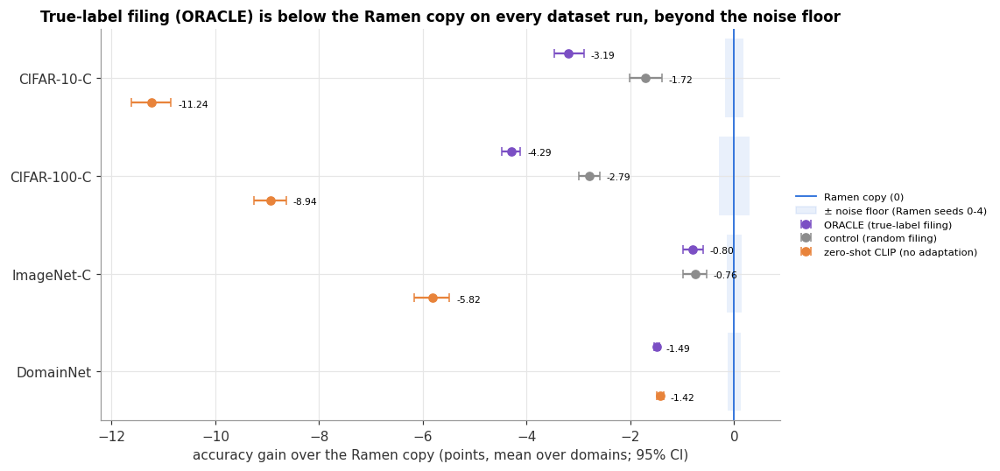

In [6]:
fig = otf.gain_figure(rows, "True-label filing (ORACLE) is below the Ramen copy on every dataset run, beyond the noise floor")

Per domain, Ramen copy → ORACLE copy (accuracy in %, from `copy_metrics.json`). The deficit covers most domains (12, 15 and 12 of 15 corruptions; all 6 DomainNet domains). On the CIFAR sets it is largest on the noise corruptions and glass blur, on ImageNet-C on frost, elastic and fog, and on DomainNet on quickdraw.

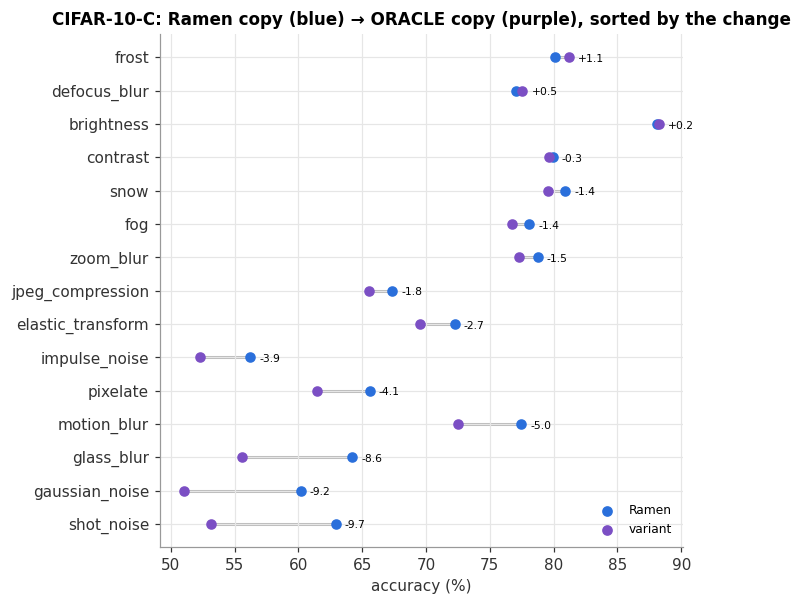

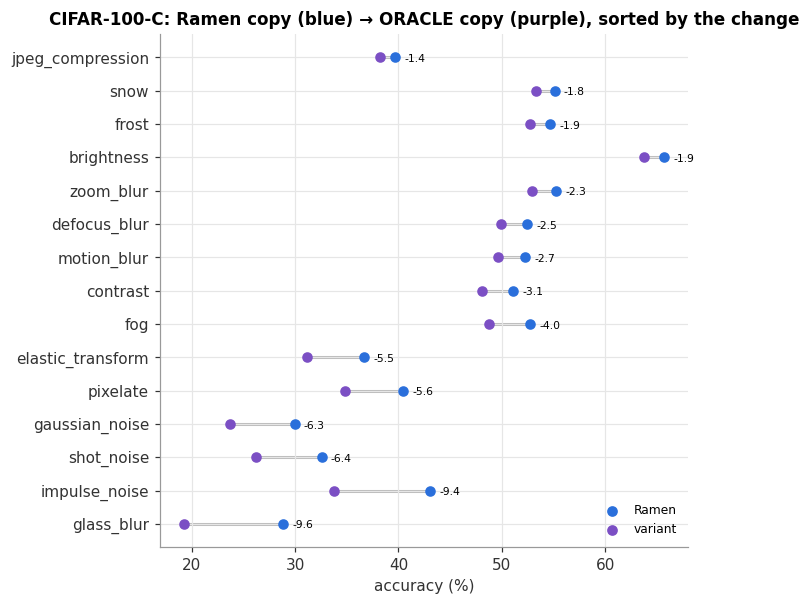

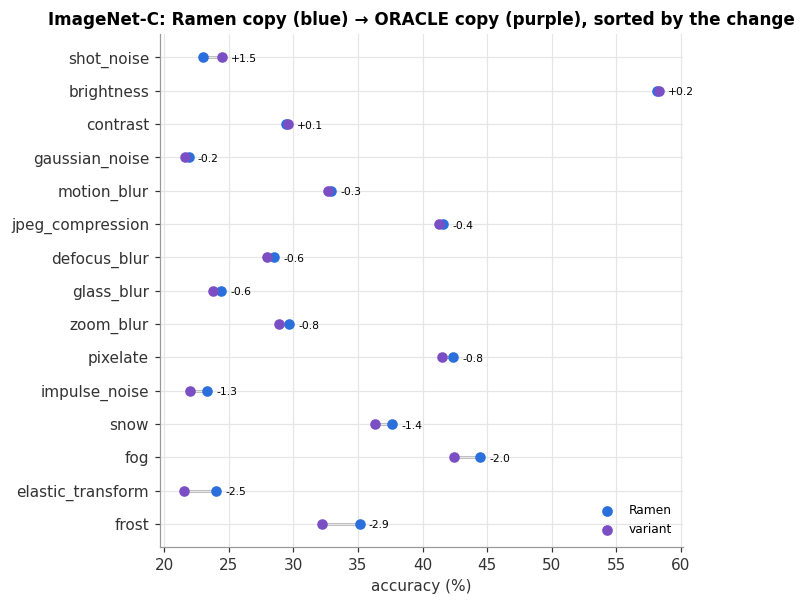

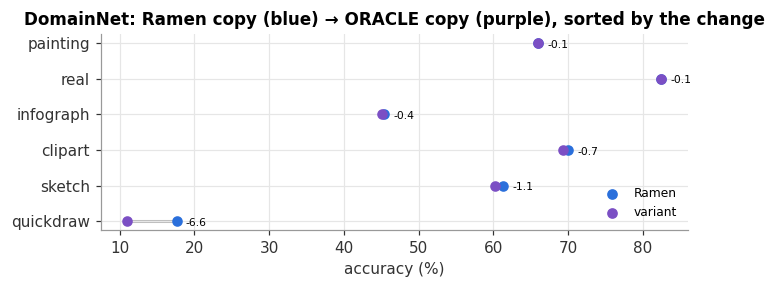

In [7]:
for d, run in RUNS.items():
    before, after = run.copy_metrics["zero_shot"]["per_domain"], run.copy_metrics["true_label"]["per_domain"]
    fig = domain_dumbbell(before, after, ["Ramen", "variant"],
                          f"{otf.DISPLAY[d]}: Ramen copy (blue) → ORACLE copy (purple), sorted by the change")

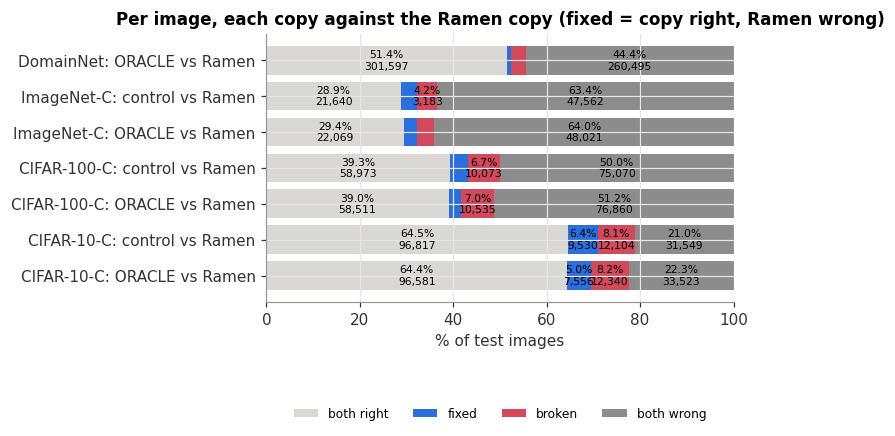

In [8]:
counts = {}
for d, run in RUNS.items():
    for copy in run.copies[1:]:
        counts[f"{otf.DISPLAY[d]}: {otf.COPY_LABEL[copy].split(' (')[0]} vs Ramen"] = otf.outcome_counts(run.correct(copy), run.correct("zero_shot"))
fig = outcome_bars(counts, "Per image, each copy against the Ramen copy (fixed = copy right, Ramen wrong)")

## 2. It is not a cold-memory effect: the ORACLE's deficit persists through the second half of the stream, when every memory is full
If the deficit came from a cold memory, it would sit at the start of the stream and shrink as the queues fill.

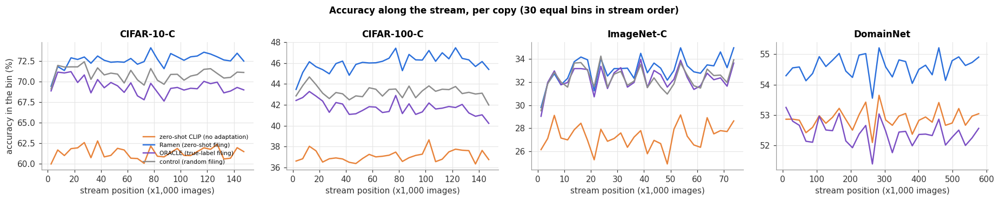

In [9]:
fig = otf.stream_figure(list(RUNS.values()))

## 3. The ORACLE copy predicts the domains' attractor classes far more often than Ramen does

TV(pred, true) is the total-variation distance between the histogram of predicted classes and of true classes (0 = the copy predicts every class exactly as often as it occurs). The **attractor** of a domain is the class zero-shot CLIP predicts most often on it; the second table gives, per domain, the share of that domain's images each copy assigns to its attractor (the true share is what a perfect classifier would give).

In [10]:
pd.DataFrame([r for run in RUNS.values() for r in otf.balance_table(run)]).set_index(["dataset", "copy"]).round(2)

TV(pred, true) %  top-5 classes' share of predictions %  true top-5 share %
dataset     copy                                                                                                       
CIFAR-10-C  zero-shot CLIP (no adaptation)              9.88                                  59.08               50.00
            Ramen (zero-shot filing)                    5.46                                  55.46               50.00
            ORACLE (true-label filing)                  7.26                                  56.46               50.00
            control (random filing)                     7.39                                  56.08               50.00
CIFAR-100-C zero-shot CLIP (no adaptation)             26.46                                  14.48                5.00
            Ramen (zero-shot filing)                   17.23                                   9.34                5.00
            ORACLE (true-label filing)                 23.63                                  13.42                5.00
            control (random filing)                    23.33                                  13.39                5.00
ImageNet-C  zero-shot CLIP (no adaptation)             31.94                                   9.78                1.16
            Ramen (zero-shot filing)                   25.25                                   2.22                1.16
            ORACLE (true-label filing)                 27.47                                   6.18                1.16
            control (random filing)                    28.79                                   8.54                1.16
DomainNet   zero-shot CLIP (no adaptation)             20.72                                  13.90                2.24
            Ramen (zero-shot filing)                   18.19                                   6.98                2.24
            ORACLE (true-label filing)                 23.19                                  17.48                2.24

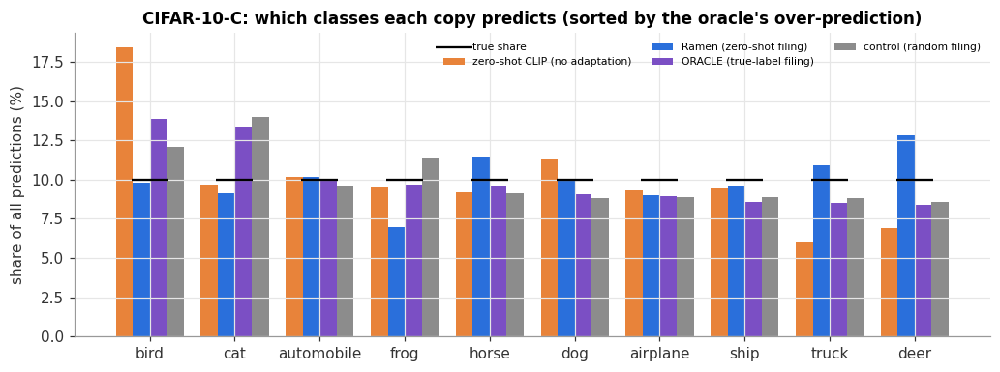

In [11]:
SRC = {d: otf.ImageSource(run) for d, run in RUNS.items()}
fig = otf.prediction_histogram_figure(RUNS["CIFAR10C"], SRC["CIFAR10C"].class_names)

In [12]:
ATTR = {d: otf.attractor_table(run, SRC[d].class_names) for d, run in RUNS.items()}
summary = []
for d, rows_d in ATTR.items():
    t = pd.DataFrame(rows_d)
    summary.append({"dataset": otf.DISPLAY[d], "domains": len(t), "mean true share %": t["true share %"].mean(),
                    **{c: t[c].mean() for c in t.columns if c not in ("dataset", "domain", "attractor", "true share %")},
                    "domains where ORACLE > Ramen": f"{int((t[otf.COPY_LABEL['true_label']] > t[otf.COPY_LABEL['zero_shot']]).sum())} of {len(t)}"})
print("mean over domains of the share of images predicted as the domain's attractor (%):")
pd.DataFrame(summary).set_index("dataset").round(2)

mean over domains of the share of images predicted as the domain's attractor (%):


,domains,mean true share %,zero-shot CLIP (no adaptation),Ramen (zero-shot filing),ORACLE (true-label filing),control (random filing),domains where ORACLE > Ramen
dataset,,,,,,,
CIFAR-10-C,15,10.00,20.20,10.60,14.57,13.12,12 of 15
CIFAR-100-C,15,1.00,7.65,2.90,5.99,5.54,15 of 15
ImageNet-C,15,0.09,7.40,0.98,4.57,4.83,13 of 15
DomainNet,6,0.47,5.93,2.28,7.86,NaN,6 of 6


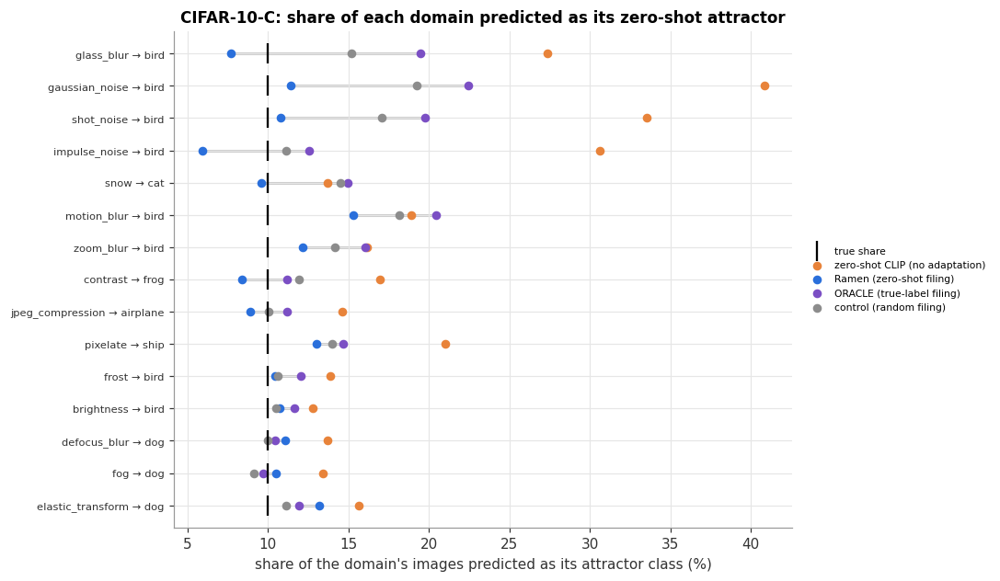

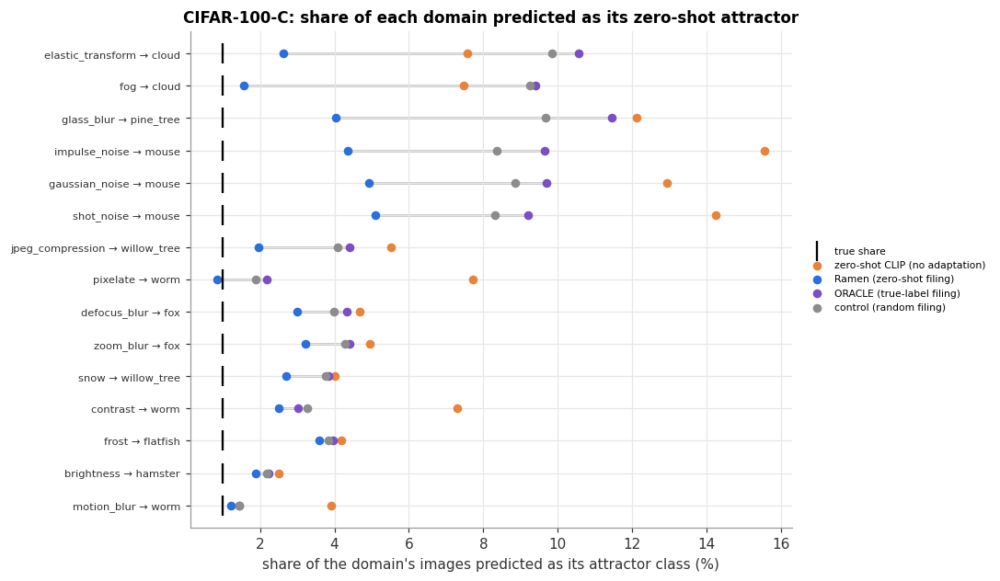

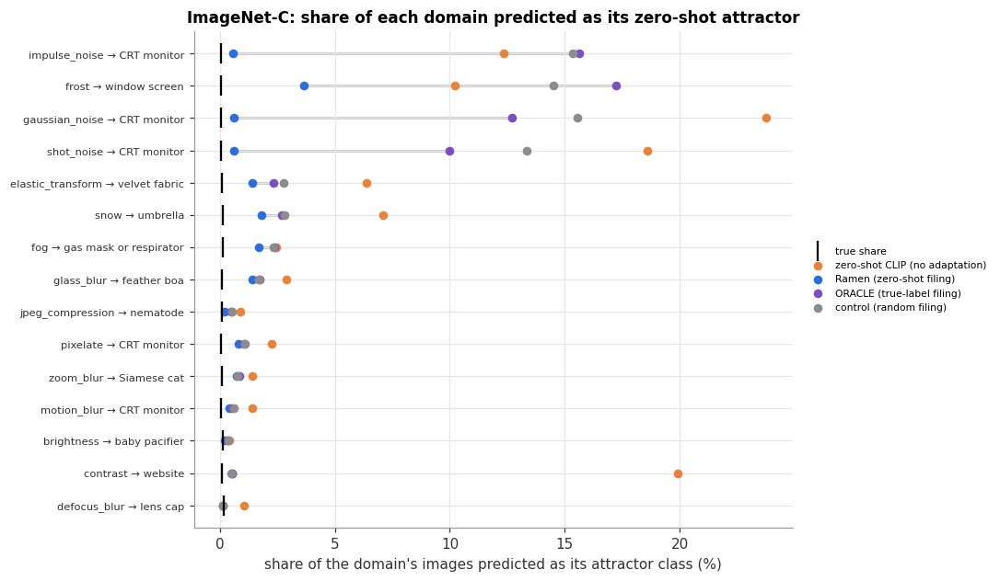

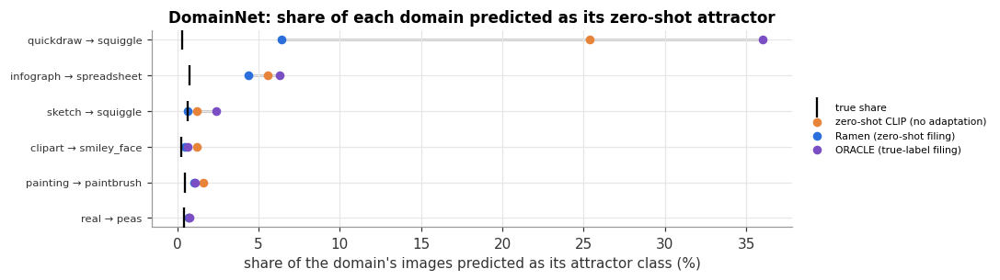

In [13]:
for d in RUNS:
    fig = otf.attractor_figure(ATTR[d], RUNS[d].copies, f"{otf.DISPLAY[d]}: share of each domain predicted as its zero-shot attractor")

## 4. Ramen's queues all push one way; the ORACLE's queues are label-pure but push toward the attractors

What the memories hold at the end of the stream (snapshot `final`, entries as stream ids looked up in the log). Ramen's memory is pure in the class each entry *pushes toward* (by construction) but mixed in true labels; the ORACLE memory is pure in true labels (by construction) but mixed in push classes, and the mix is not random: the attractor columns fill up.

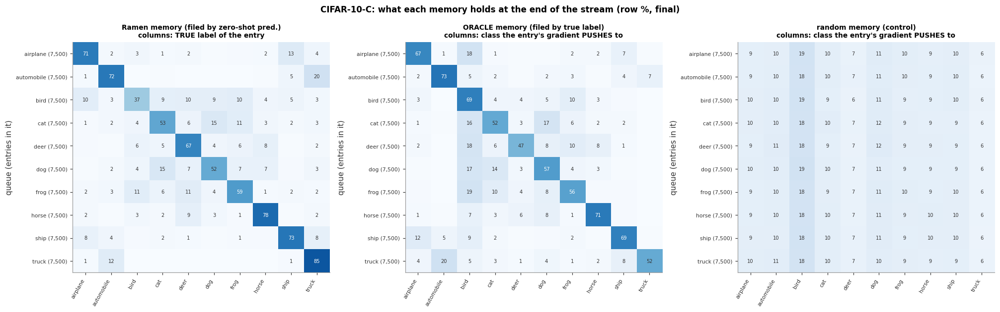

In [14]:
fig = otf.memory_heatmap_figure(RUNS["CIFAR10C"], SRC["CIFAR10C"].class_names)

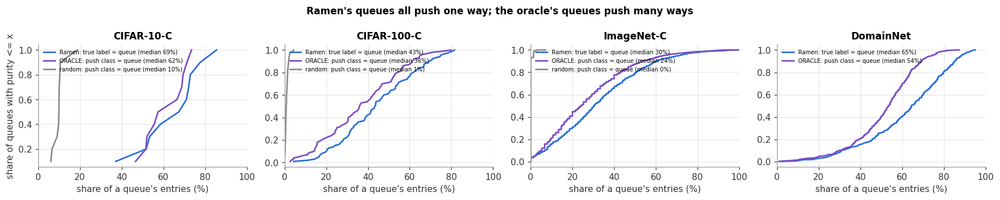

In [15]:
fig = otf.purity_figure(list(RUNS.values()))

The memories as images (CIFAR-10-C, 8 random entries per queue, seeded). Thumbnail caption: true class / zero-shot class. Orange border: the other memory holds this image in a *different* queue (zero-shot class ≠ true class). Dashed border: the other memory does not hold it at all, which happens because the two memories' queues fill and freeze (fp16 priorities, `lab.md` §7) at different stream positions.

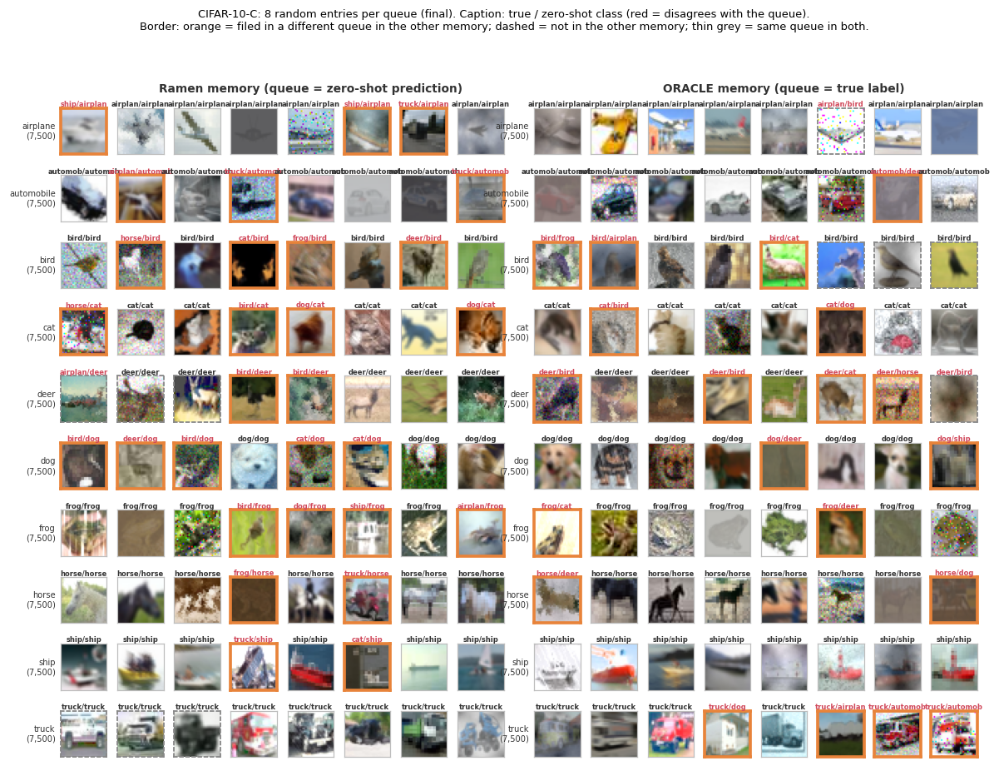

In [16]:
fig = otf.memory_gallery_figure(RUNS["CIFAR10C"], SRC["CIFAR10C"])

## 5. The ORACLE's active sets lose Ramen's balance: about 2-5x more weight on a single push class, and on the images it breaks several times more weight toward the query's wrong zero-shot answer

Per query, each copy's active set (its $S_i$) is summarised by the share of its weight $w_{ij}$ on entries with a given property (`ramen_lab/methods/multi_cache_log.py`). "Push class" = the entry's zero-shot class, the class its stored entropy gradient pushes toward. Groups: all images, and the images where the ORACLE copy differs from the Ramen copy.

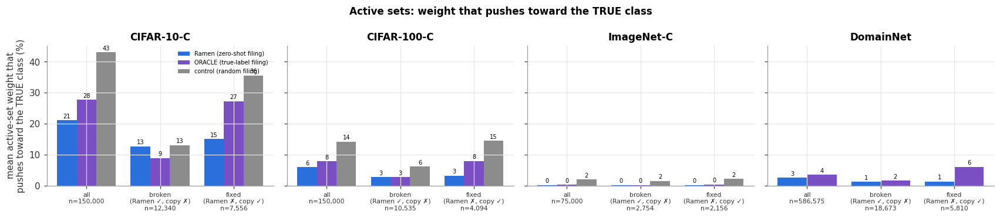

In [17]:
fig = otf.mechanism_figure(list(RUNS.values()), "share_push_true")

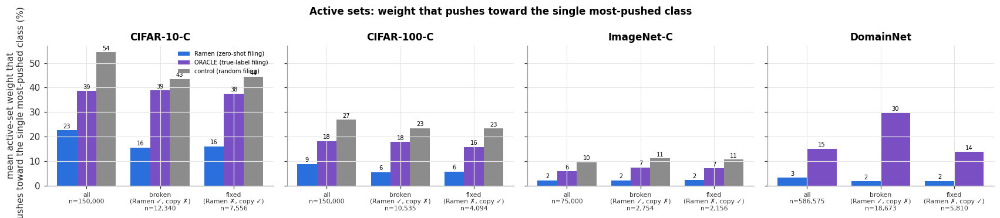

In [18]:
fig = otf.mechanism_figure(list(RUNS.values()), "share_push_top")

In [19]:
mech = pd.DataFrame([r for run in RUNS.values() for r in otf.mechanism_table(run)])
mech[mech["samples"].isin(["all", "broken (Ramen ✓, copy ✗)", "fixed (Ramen ✗, copy ✓)"])].set_index(["dataset", "samples", "copy"]).round(1)

n  pushes toward the TRUE class  pushes toward the query's zero-shot class  pushes toward the copy's own prediction  \
dataset     samples                  copy                                                                                                                                                   
CIFAR-10-C  all                      Ramen (zero-shot filing)    150000                          21.1                                       22.0                                     21.6   
                                     ORACLE (true-label filing)  150000                          27.7                                       34.9                                     32.4   
                                     control (random filing)     150000                          43.1                                       50.4                                     48.7   
            broken (Ramen ✓, copy ✗) Ramen (zero-shot filing)     12340                          12.7                                       14.6                                     12.7   
                                     ORACLE (true-label filing)   12340                           8.9                                       32.1                                     30.0   
                                     control (random filing)      12340                          13.1                                       36.8                                     33.5   
            fixed (Ramen ✗, copy ✓)  Ramen (zero-shot filing)      7556                          15.1                                       15.2                                     12.4   
                                     ORACLE (true-label filing)    7556                          27.3                                       30.9                                     27.3   
                                     control (random filing)       7556                          35.6                                       37.7                                     35.6   
CIFAR-100-C all                      Ramen (zero-shot filing)    150000                           6.0                                        7.2                                      6.8   
                                     ORACLE (true-label filing)  150000                           7.9                                       13.8                                     12.5   
                                     control (random filing)     150000                          14.2                                       21.3                                     20.3   
            broken (Ramen ✓, copy ✗) Ramen (zero-shot filing)     10535                           2.8                                        3.4                                      2.8   
                                     ORACLE (true-label filing)   10535                           2.8                                       11.2                                     10.7   
                                     control (random filing)      10535                           6.2                                       15.8                                     14.9   
            fixed (Ramen ✗, copy ✓)  Ramen (zero-shot filing)      4094                           3.3                                        3.8                                      2.7   
                                     ORACLE (true-label filing)    4094                           8.0                                       10.2                                      8.0   
                                     control (random filing)       4094                          14.5                                       16.4                                     15.3   
ImageNet-C  all                      Ramen (zero-shot filing)     75000                           0.3                                        0.2                                      0.3   
                                     ORACLE (true-label filing)   75000                           0.4

What the broken images were before adaptation: did the ORACLE copy fail to *fix* a zero-shot error that Ramen fixed, or did it *break* a correct zero-shot answer? (And the reverse for the images it fixed.)

In [20]:
pd.DataFrame([r for run in RUNS.values() for c in run.copies[1:] for r in otf.broken_breakdown(run, c)]).set_index(["dataset", "copy", "images"])

n the wrong one zero-shot wrong; the wrong one repeats it zero-shot wrong; the wrong one says another wrong class  \
dataset     copy                       images                                                                                                                                                   
CIFAR-10-C  ORACLE (true-label filing) broken: Ramen right, copy wrong  12340          copy                             7,164 (58.1%)                                      3,523 (28.5%)        
                                       fixed: Ramen wrong, copy right    7556         Ramen                             1,094 (14.5%)                                      2,121 (28.1%)        
            control (random filing)    broken: Ramen right, copy wrong  12104          copy                             6,486 (53.6%)                                      3,797 (31.4%)        
                                       fixed: Ramen wrong, copy right    9530         Ramen                             1,960 (20.6%)                                      2,751 (28.9%)        
CIFAR-100-C ORACLE (true-label filing) broken: Ramen right, copy wrong  10535          copy                             4,067 (38.6%)                                      4,388 (41.7%)        
                                       fixed: Ramen wrong, copy right    4094         Ramen                               749 (18.3%)                                      1,465 (35.8%)        
            control (random filing)    broken: Ramen right, copy wrong  10073          copy                             3,758 (37.3%)                                      4,064 (40.3%)        
                                       fixed: Ramen wrong, copy right    5884         Ramen                             1,438 (24.4%)                                      2,065 (35.1%)        
ImageNet-C  ORACLE (true-label filing) broken: Ramen right, copy wrong   2754          copy                               953 (34.6%)                                      1,174 (42.6%)        
                                       fixed: Ramen wrong, copy right    2156         Ramen                               424 (19.7%)                                        932 (43.2%)        
            control (random filing)    broken: Ramen right, copy wrong   3183          copy                             1,073 (33.7%)                                      1,333 (41.9%)        
                                       fixed: Ramen wrong, copy right    2615         Ramen                               614 (23.5%)                                      1,017 (38.9%)        
DomainNet   ORACLE (true-label filing) broken: Ramen right, copy wrong  18673          copy                             8,637 (46.3%)                                      3,385 (18.1%)        
                                       fixed: Ramen wrong, copy right    5810         Ramen                             1,916 (33.0%)                                        776 (13.4%)        

                                                                       zero-shot right; the wrong one broke it  
dataset     copy                       images                                                                   
CIFAR-10-C  ORACLE (true-label filing) broken: Ramen right, copy wrong                           1,653 (13.4%)  
                                       fixed: Ramen wrong, copy right                            4,341 (57.5%)  
            control (random filing)    broken: Ramen right, copy wrong                           1,821 (15.0%)  
                                       fixed: Ramen wrong, copy right                            4,819 (50.6%)  
CIFAR-100-C ORACLE (true-label filing) broken: Ramen right, copy wrong                           2,080 (19.7%)  
                                       fixed: Ramen wrong, copy right                            1,880 (45.9%)  
            control (random filing)    broken: Ramen right, copy wrong             

## 6. Examples: Ramen right, ORACLE wrong

The run kept a uniform random sample (reservoir, seeded) of 48 images per category over the whole stream, with every copy's full active set. The examples below are the **first ones in that sample, not picked by hand**. For each: the query, where each active set pushes (weight share by push class; ★ = true class), and the two active sets side by side: rows = the queues carrying the most weight, each showing its top entries by weight. Orange border = the image is **not** in the other copy's active set. Caption = true class → push class, red when the push is away from the query's true class.

In [21]:
names = SRC["CIFAR10C"].class_names
ex = pd.DataFrame(otf.example_tables(RUNS["CIFAR10C"], "broken"))
for col in ("true", "zero-shot", "Ramen pred", "ORACLE pred"):
    ex[col] = ex[col].map(lambda c: names[c])
print(f"CIFAR-10-C broken images in the run: {int(RUNS['CIFAR10C'].log['ex_broken__seen']):,}; sample kept: {len(ex)}")
ex.head(12).set_index("example").round(1)

CIFAR-10-C broken images in the run: 12,340; sample kept: 48


,stream_id,domain,true,zero-shot,Ramen pred,ORACLE pred,active set size,shared entries %
example,,,,,,,,
0,102103,shot_noise,dog,bird,dog,bird,500,39.4
1,101327,elastic_transform,horse,cat,horse,cat,500,54.6
2,64106,fog,deer,frog,deer,frog,500,38.8
3,143882,impulse_noise,airplane,bird,airplane,bird,500,41.2
4,49897,contrast,deer,frog,deer,frog,500,56.4
5,142661,gaussian_noise,ship,airplane,ship,airplane,500,46.0
6,65070,pixelate,deer,deer,deer,bird,500,47.8
7,48832,impulse_noise,truck,automobile,truck,automobile,500,54.0
8,35089,defocus_blur,dog,bird,dog,bird,500,58.8


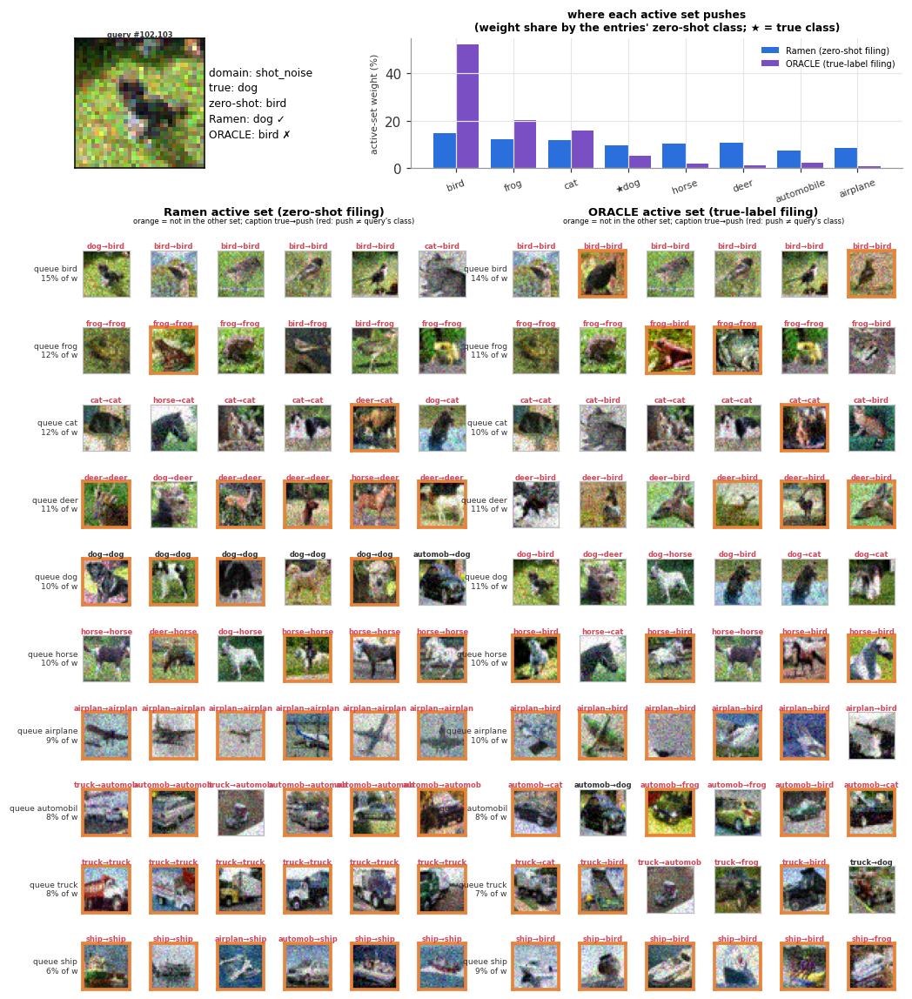

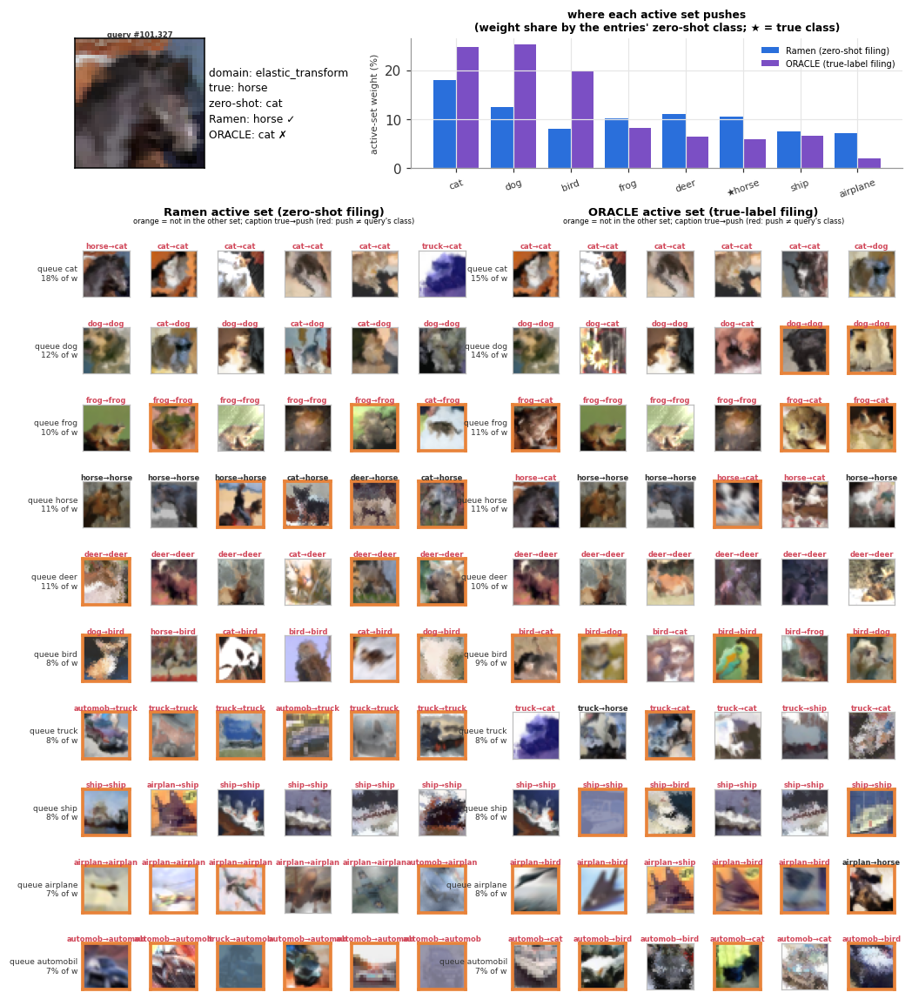

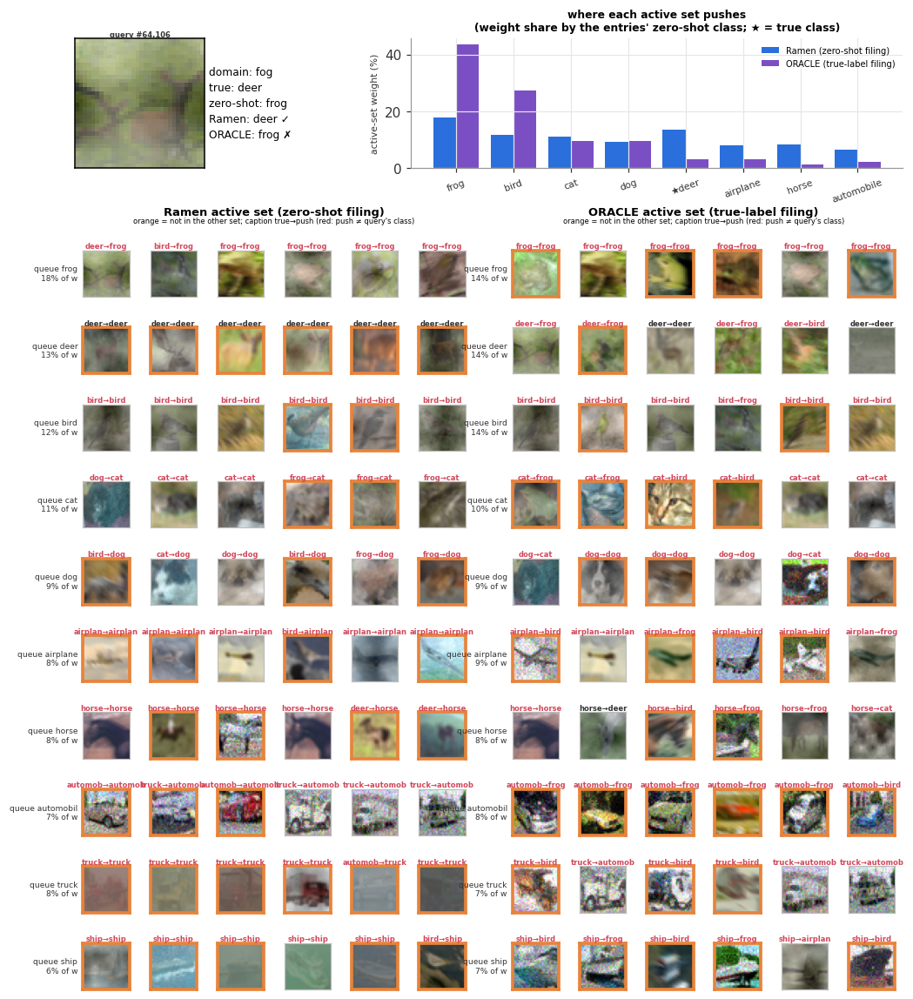

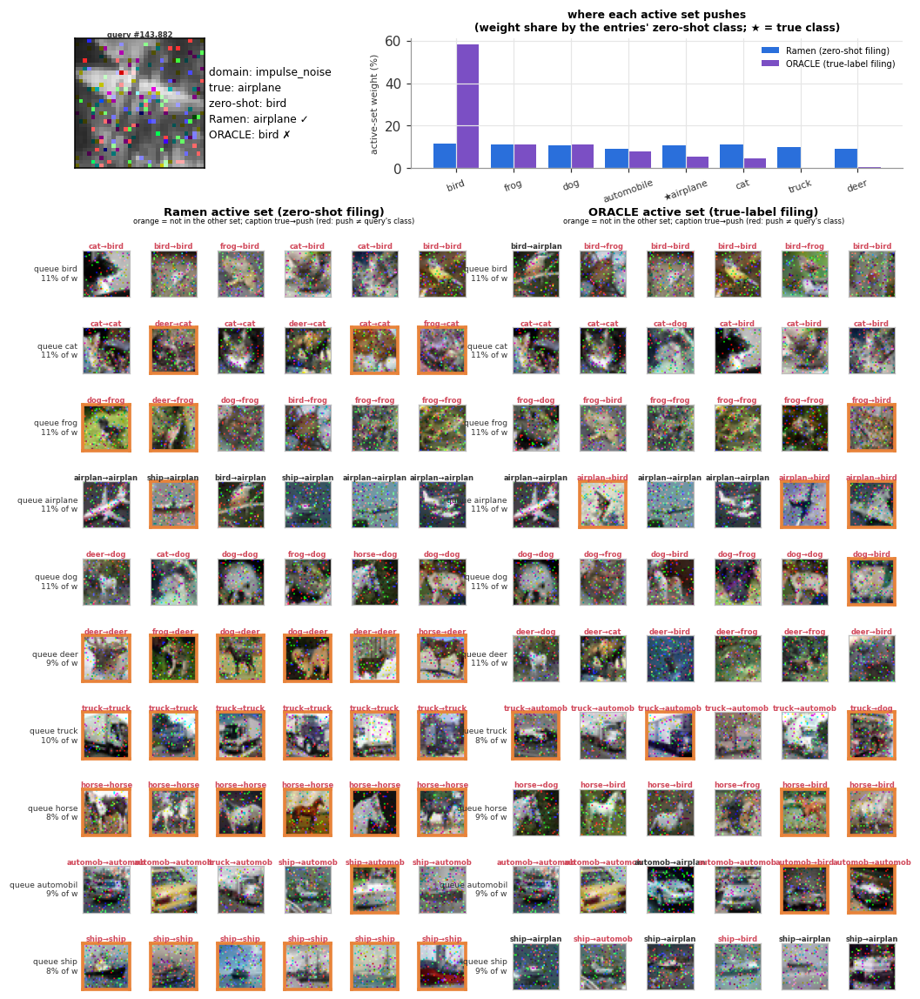

In [22]:
for i in range(4):
    fig = otf.example_figure(RUNS["CIFAR10C"], SRC["CIFAR10C"], "broken", i)

For contrast, the first sampled image the ORACLE copy gets right and Ramen gets wrong:

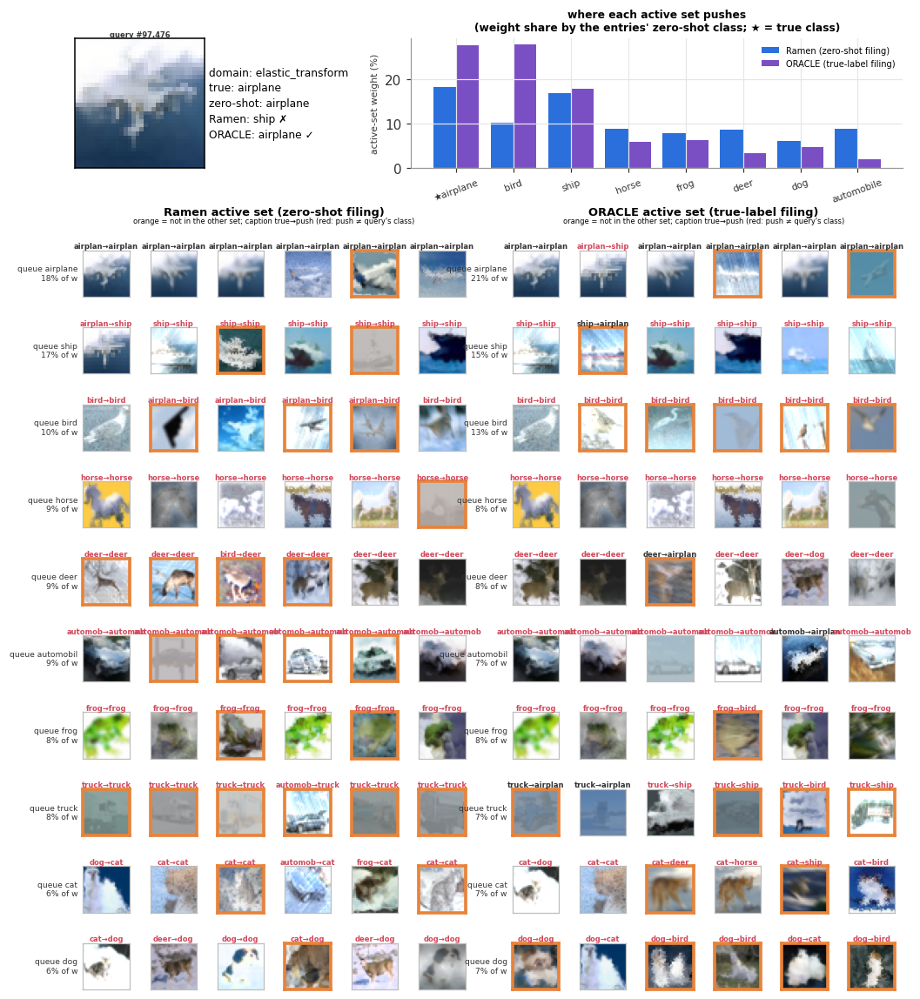

In [23]:
fig = otf.example_figure(RUNS["CIFAR10C"], SRC["CIFAR10C"], "fixed", 0)

CIFAR-100-C and ImageNet-C: the first sampled image of each where Ramen is right and the ORACLE is wrong; rows = the 8 queues carrying the most weight in either active set. ImageNet-C retrieves $k$ = 1 entry per queue, so each of its rows holds one image.

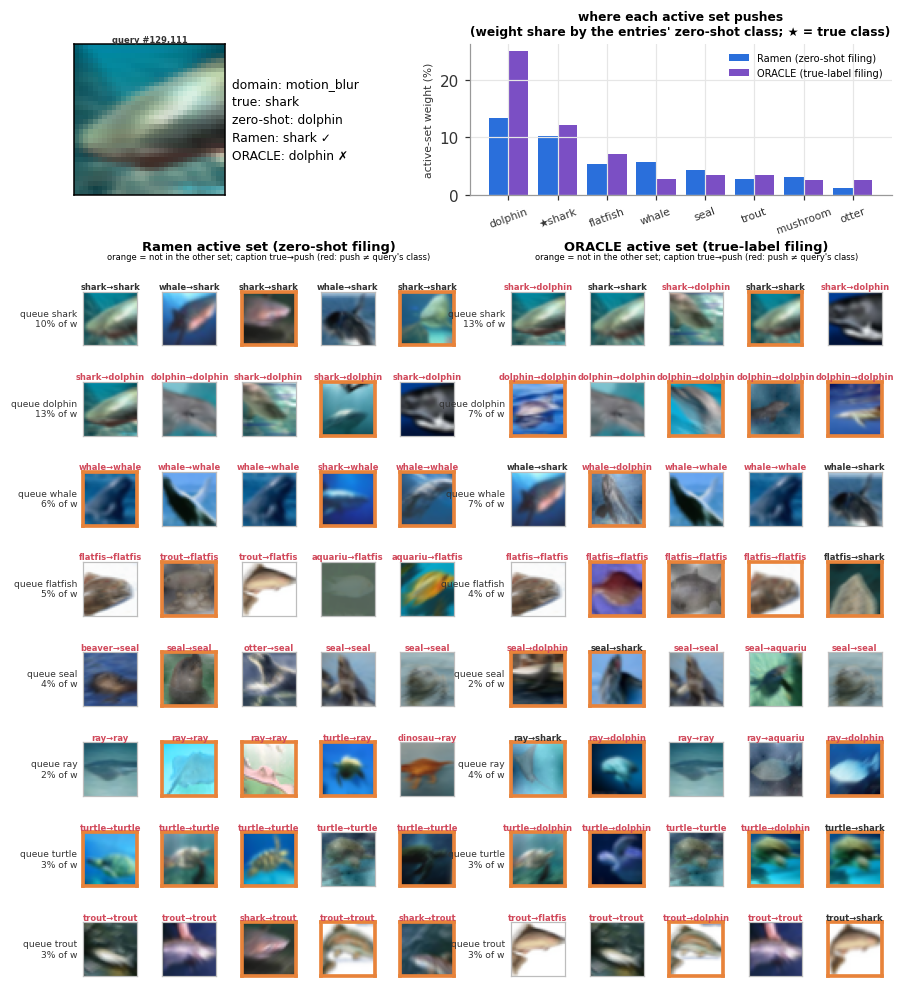

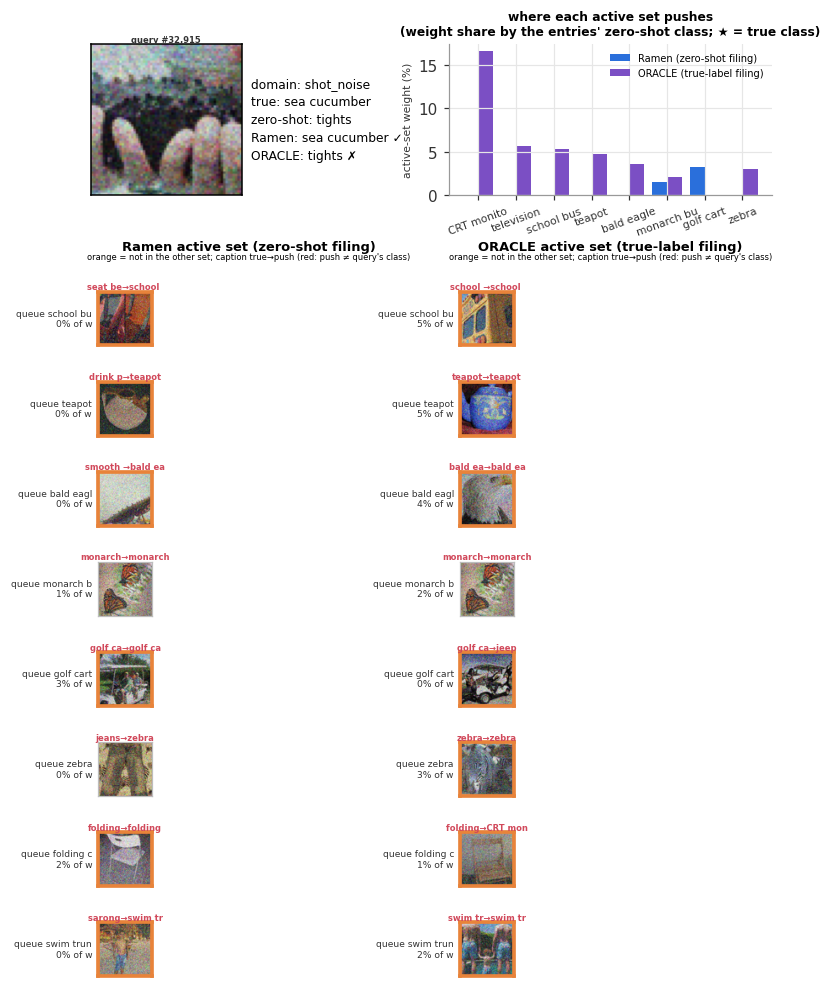

In [24]:
for d in ("CIFAR100C", "ImageNetC5K"):
    if d in RUNS:
        fig = otf.example_figure(RUNS[d], SRC[d], "broken", 0, per_queue=5 if d == "CIFAR100C" else 4, n_queues=8)

## 7. DomainNet: Ramen's attractor queues are quickdraw drawings of many classes that all push one way; in the ORACLE memory the same kind of drawings sit in their true-class queues and still push toward "squiggle", from almost every queue

DomainNet has 345 classes, so the memories are shown for a subset of queues chosen by rule, not by eye: each domain's zero-shot **attractor** (the class zero-shot CLIP predicts most on that domain) and the 6 further classes the ORACLE copy over-predicts most relative to the Ramen copy. The run keeps two copies here (Ramen and ORACLE); the random control did not fit in GPU memory next to DomainNet's memory (345 queues × 300 entries).

In [25]:
dn, dn_names = RUNS["DomainNet"], SRC["DomainNet"].class_names
attractors = list(dict.fromkeys(dn_names.index(a) for a in pd.DataFrame(ATTR["DomainNet"])["attractor"]))
over = otf.prediction_shares(dn, "true_label") - otf.prediction_shares(dn, "zero_shot")
extra = [int(c) for c in np.argsort(-over) if c not in attractors][:6]
SHOW = attractors + extra
true_share = np.bincount(dn.log["label"], minlength=345) / len(dn.log["label"])
role = {c: "attractor of " + ", ".join(r["domain"] for r in ATTR["DomainNet"] if r["attractor"] == dn_names[c]) for c in attractors}
pd.DataFrame([{"class": dn_names[c], "why shown": role.get(c, "ORACLE over-predicts"),
               "true share %": 100 * true_share[c],
               **{f"{otf.COPY_LABEL[k]} predicts %": 100 * otf.prediction_shares(dn, k)[c] for k in ["zero_shot_init"] + dn.copies}}
              for c in SHOW]).set_index("class").round(2)

,why shown,true share %,zero-shot CLIP (no adaptation) predicts %,Ramen (zero-shot filing) predicts %,ORACLE (true-label filing) predicts %
class,,,,,
smiley_face,attractor of clipart,0.23,1.04,0.66,0.82
spreadsheet,attractor of infograph,0.43,0.81,0.68,0.86
paintbrush,attractor of painting,0.23,0.28,0.19,0.19
squiggle,"attractor of quickdraw, sketch",0.29,7.72,2.05,11.09
peas,attractor of real,0.26,0.34,0.35,0.35
envelope,ORACLE over-predicts,0.31,2.72,1.17,2.56
pear,ORACLE over-predicts,0.30,1.45,1.23,2.09
circle,ORACLE over-predicts,0.29,0.67,0.61,0.76
triangle,ORACLE over-predicts,0.34,0.76,0.60,0.72


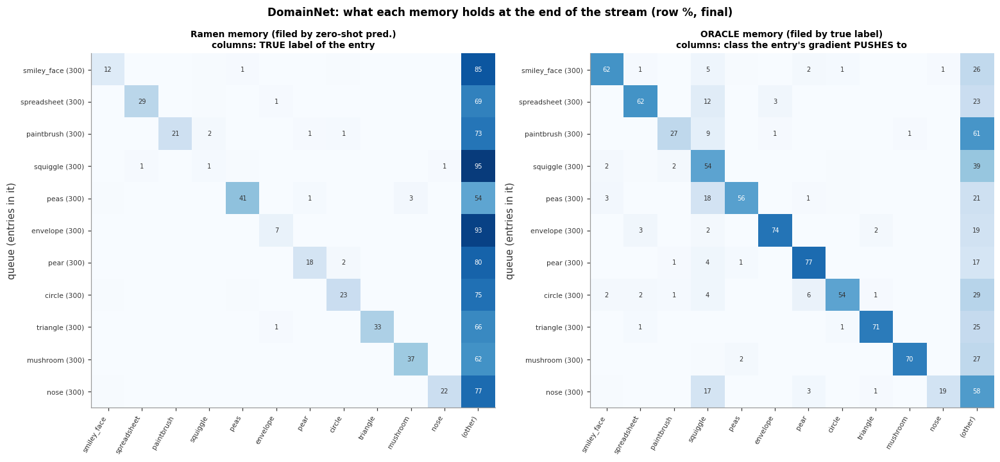

In [26]:
fig = otf.memory_heatmap_figure(dn, dn_names, classes=SHOW)

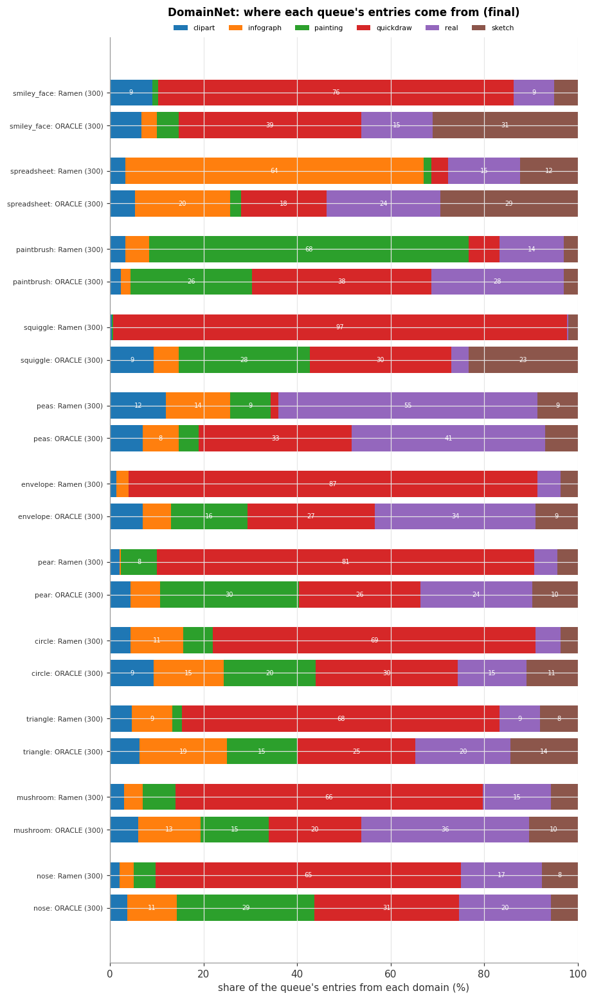

In [27]:
fig = otf.queue_domain_figure(dn, dn_names, SHOW)

The two memories as images, for the same queues (7 random entries per queue, seeded). Caption: domain: true class / zero-shot class, red where it disagrees with the queue. Orange border: the other memory holds the image in a different queue; dashed: the other memory does not hold it.

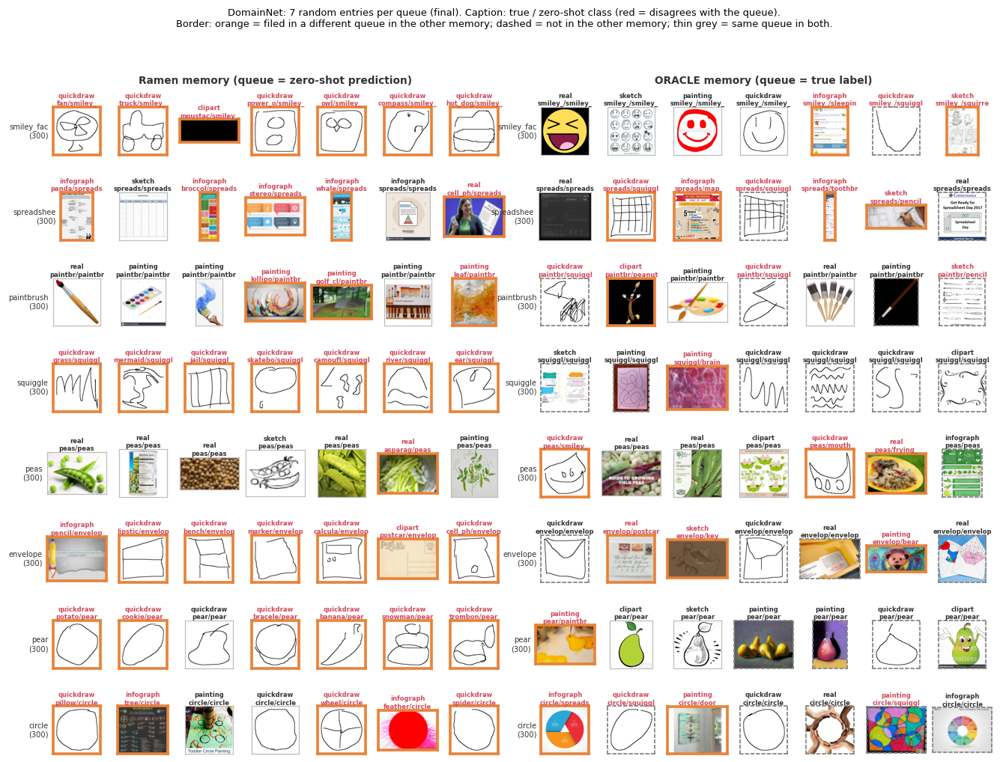

In [28]:
fig = otf.memory_gallery_figure(dn, SRC["DomainNet"], queues=SHOW[:8], per_queue=7)

DomainNet examples, Ramen right and ORACLE wrong: the first three in the run's uniform sample (not picked by hand); rows = the 8 queues carrying the most weight in either active set ($k$ = 10 per queue, top 6 shown).

In [29]:
names = SRC["DomainNet"].class_names
ex = pd.DataFrame(otf.example_tables(dn, "broken"))
for col in ("true", "zero-shot", "Ramen pred", "ORACLE pred"):
    ex[col] = ex[col].map(lambda c: names[c])
print(f"DomainNet broken images in the run: {int(dn.log['ex_broken__seen']):,}; sample kept: {len(ex)}")
ex.head(8).set_index("example").round(1)

DomainNet broken images in the run: 18,673; sample kept: 48


,stream_id,domain,true,zero-shot,Ramen pred,ORACLE pred,active set size,shared entries %
example,,,,,,,,
0,326772,quickdraw,spider,spider,spider,ant,3450,17.6
1,312988,quickdraw,boomerang,boomerang,boomerang,squiggle,3450,8.4
2,227612,quickdraw,duck,duck,duck,swan,3450,13.3
3,387349,quickdraw,bat,squiggle,bat,squiggle,3450,12.0
4,463334,quickdraw,book,squiggle,book,squiggle,3450,13.2
5,554070,clipart,stairs,zigzag,stairs,zigzag,3450,15.7
6,532869,quickdraw,star,squiggle,star,squiggle,3450,10.2
7,458990,quickdraw,mountain,mountain,mountain,pear,3450,18.3


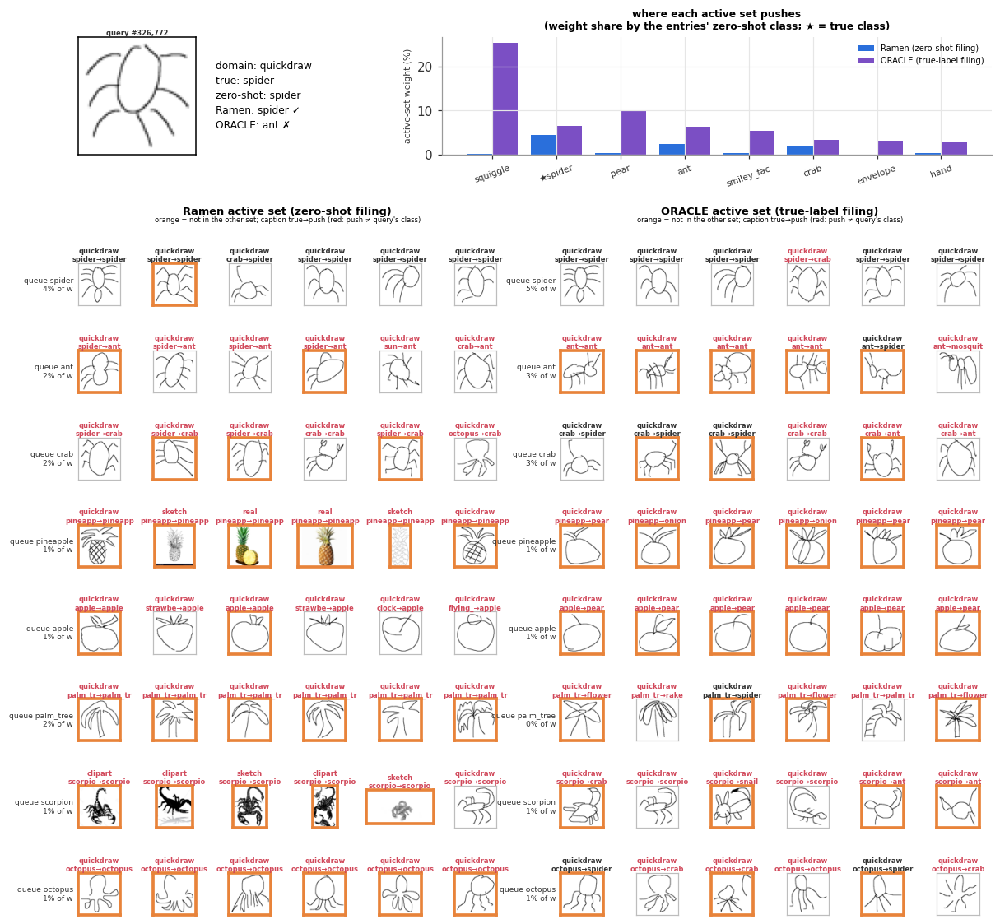

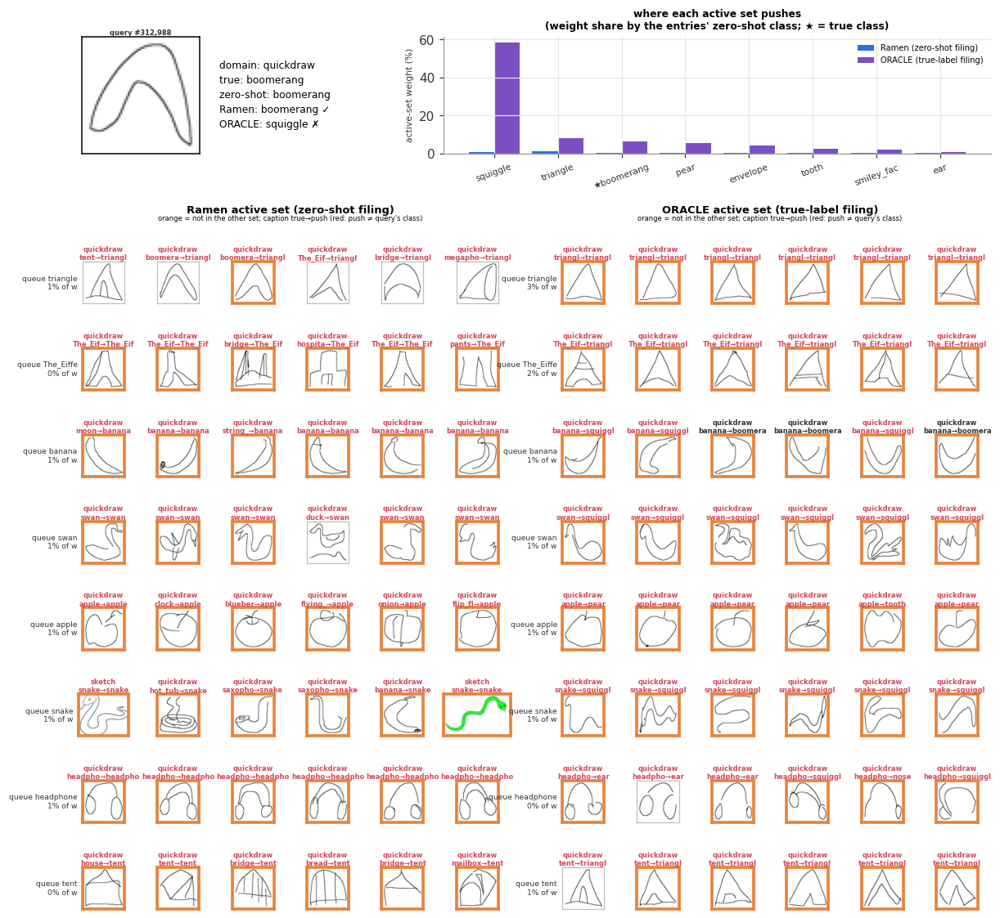

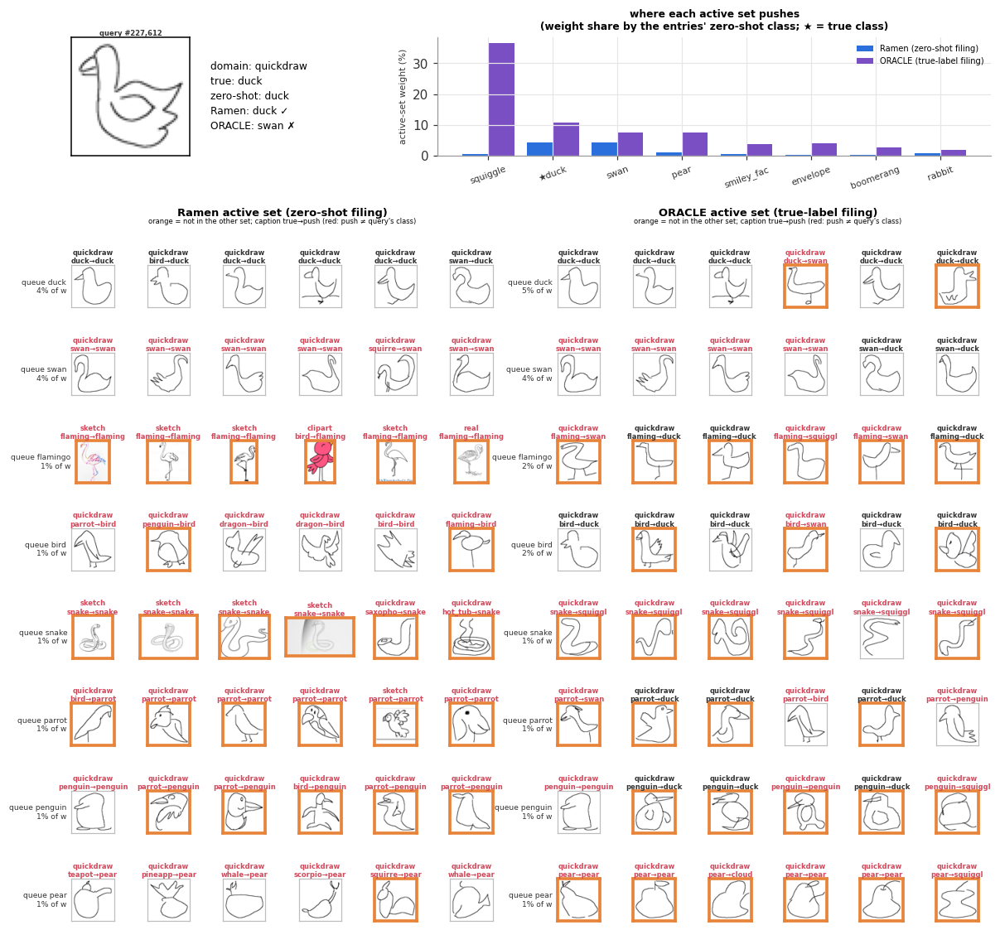

In [30]:
for i in range(3):
    fig = otf.example_figure(dn, SRC["DomainNet"], "broken", i, per_queue=6, n_queues=8)

## Interpretation

**What the numbers say.** On all four datasets (seed 0), filing every image under its true class gives *lower* accuracy than Ramen's zero-shot filing, by far more than the noise floor (section 1). On DomainNet it is even slightly below zero-shot CLIP, almost all of it on quickdraw. The pre-registered hypothesis holds on CIFAR-10-C, and the same holds on CIFAR-100-C, ImageNet-C and DomainNet. A random filing, which uses no label information at all, is also below Ramen but **above** the ORACLE on both CIFAR sets, and level with it on ImageNet-C (overlapping CIs). By the pre-registered reading, the label information in the filing is not used by the update. On the CIFAR sets it is actively harmful.

**Mechanism (supported by the logs, with one `[hypothesis]`).**
1. *What an entry does does not depend on where it is filed.* The stored value $g_j$ is the entropy gradient at $\theta_0$; it makes the model more confident in $j$'s **zero-shot** class $\hat y_j$ (its push class). Filing changes only *which* entries are retrieved together.
2. *Ramen's filing balances the push; true filing balances the labels.* Every Ramen queue pushes one way (its own class), so the active set holds $k$ entries pushing toward each class. That is the paper's prediction balance (§3.2; App. B: the bias part of the update cancels). In the ORACLE memory each queue is label-pure but mixed in push class (section 4). The mix is not random: on a corrupted domain, the same-class neighbours of a query (and the query's *own* true-class queue, example 2) are mostly misread by zero-shot CLIP as the domain's **attractor** class ("bird" on CIFAR-10-C noise, "CRT monitor" on ImageNet-C noise, "squiggle" on DomainNet quickdraw).
3. *So the ORACLE's step loses the balance.* Its active sets put about 2-5 × more weight on a single push class than Ramen's (section 5, `share_push_top`). On the images it breaks, they push toward the query's own (wrong) zero-shot answer several times more than Ramen's do. Its predictions drift back toward the domain attractors that Ramen had removed (section 3); on DomainNet quickdraw the ORACLE predicts "squiggle" even more often than zero-shot CLIP does. Most broken images (64-87%) were zero-shot errors that Ramen corrected and the ORACLE did not; on CIFAR-10-C the ORACLE mostly just repeated the zero-shot answer.
4. *What this does not explain: why random filing hurts less than the ORACLE.* The random copy's active sets are even *more* concentrated (highest `share_push_top` and `share_push_zs` on every dataset where it ran), so concentration alone cannot be the whole story. `[hypothesis]` A random queue is a random 1/C slice of the stream, so its top-$k$ are the query's nearest neighbours and mostly push toward the query's *own* zero-shot class (self-training-like). The ORACLE's top-$k$ per true class are same-domain images of *other* classes, and they push toward the domain's attractor. The only support so far is that the ORACLE predicts the attractor somewhat more often than random on both CIFAR sets (section 3). A direct test would split each copy's push weight, per query, into "the query's own zero-shot class" vs. "the domain attractor".

**What the numbers do not say.**
- Seed 0 only. The gaps are about 6-17 × the floors, so a sign flip across seeds is very unlikely, but per-domain claims need their own spread.
- DomainNet has no random control (GPU memory), so whether the ORACLE is also below random there is unknown.
- The ORACLE changes only the filing. An oracle that also changed the *stored value* (e.g. a cross-entropy gradient toward $y_j$) is a different experiment and is not ruled out here.
- The active-set statistics weight entries by $w_{ij}$ and ignore $\lVert g_j\rVert$. They describe which entries are retrieved, not the exact sign pattern of $G_i$.

**Consequence for the direction.** Any idea that only makes the memory's *labels* cleaner (purity fixes, better pseudo-labels for filing, relabelling) has a negative ceiling under Ramen's update: even perfect labels lose 0.8-4.3 points. This confirms the closed row in `docs/research_state.md` on `pc2_lab`, at the fixed batch and with Ramen's own write timing. What matters is the balance of the **push** directions in the active set, not the labels of its members.

**Next step and stop rule.** The useful lever, if any, is the push balance. A label-free test would cap each active set's weight per push class, so no class can take more than $1/|\mathcal C^+|$ of it, and run that on Ramen itself. Pre-registered gate: CIFAR-10-C seed 0 above Ramen by more than the floor (0.18). Stop if it is within the floor on CIFAR-10-C and CIFAR-100-C.

## Glossary

| term | meaning |
|---|---|
| $z_i$ | L2-normalised CLIP image embedding of test image $i$ at the pretrained weights; the memory key |
| $\hat y_i$ | zero-shot prediction (argmax of $p_i$ at $\theta_0$) |
| $y_i$ | true label (ORACLE only) |
| $H_i$ | entropy of the zero-shot prediction; enters the retrieval weight as $e^{-H_j}$ |
| $g_i$ | per-sample gradient of $H_i$ w.r.t. the LayerNorm affine parameters at $\theta_0$; the memory value ($D$ = 39,936 numbers) |
| $t_i$ | arrival counter, stored as fp16 priority; the oldest (lowest) entry is evicted from a full queue |
| $K$, $k$, $\beta$, $\eta$ | queue capacity, entries retrieved per queue, distance temperature, SignSGD step size (`cfg/<dataset>/Ramen.yaml`) |
| queue / filing | Ramen's memory is one FIFO queue per class; *filing* = choosing the queue an entry is written into |
| active set $S_i$ | the per-query support set: the $k$ entries nearest to $z_i$ from every non-empty queue (paper §3.2, Eq. 2) |
| $w_{ij}$ | retrieval weight $e^{-H_j}e^{-\beta\lVert z_i-z_j\rVert}$ of entry $j$ for query $i$ |
| $G_i$ | weighted, queue-averaged sum of the active set's gradients; the step is $-\eta\,\mathrm{sign}(G_i)$ |
| push class | an entry's zero-shot class $\hat y_j$: its stored gradient $g_j$ lowers $j$'s entropy, i.e. makes $j$ more confident in $\hat y_j$ |
| prediction balance | the active set has the same number of entries pushing toward every class (true under zero-shot filing; paper §3.2, App. B) |
| attractor (class) | on a given domain, the class zero-shot CLIP predicts far more often than it occurs (e.g. "bird" on CIFAR-10-C noise) |
| copy | one of the memories kept by `RamenMultiCache` in the same run; each copy predicts every image |
| Ramen copy | the zero-shot-filed copy: bit-identical to upstream Ramen (tests and sanity table) |
| ORACLE copy | the copy filed by true label; reads labels, so it is an upper-bound style diagnostic, not a method |
| control (random filing) | the copy filed under a uniformly random class (seeded): spreads entries like the oracle, without label information |
| fixed / broken | per image vs. the Ramen copy: the copy is right where Ramen is wrong / wrong where Ramen is right |
| TV(pred, true) | total-variation distance between the predicted-class and true-class histograms, in % (0 = same histogram) |
| noise floor | 2 × (max − min) of Ramen's headline accuracy over seeds 0-4 at the fixed batch (week-01 baseline) |
| cluster bootstrap | CI that resamples whole base images (all their corruptions together) because they are not independent |
| fp16 priority freeze | priorities are fp16; past 65,504 they become `inf`, and a queue full of `inf` entries accepts nothing new (`lab.md` §7) |
| gradient pool | `GradientPool`: each sample's gradient stored once on the GPU and referenced by every copy's queues |
| snapshot | every copy's queues as stream ids, saved at 25 / 50 / 75 % of the stream and at the end |
| reservoir sample | uniform random sample over the whole stream (Algorithm R), used to pick examples without hand selection |